# 01 · Footprint — How big is each Big 4 institution?

**NC3 · Lansing Economic Ecosystem and Community Wealth Analysis** — working notebook (wangz153)

This is the first of three analysis notebooks, ordered by the question each one answers:

| Notebook | Question | Research question |
|---|---|---|
| **01 Footprint** (this one) | How big is each institution in the local economy? | RQ1 |
| 02 Retention | How much of that activity stays in the region (wages, suppliers, taxes)? | RQ1, RQ2 |
| 03 Benefit | What do residents actually get, and where is the mismatch? | RQ3 |

Data gaps found along the way are logged at the end of each notebook (RQ4).

### Indicators in this notebook

| ID | Indicator | Definition |
|---|---|---|
| E1 | Direct employment | Jobs at the institution in the region, reported as a **low–high range** |
| E2 | Share of regional jobs | E1 ÷ all covered jobs in the region |
| E3 | Relative pay | Institution average annual pay ÷ regional average annual pay |
| E4 | Employment trend | Change 2019 → 2025 (2019 = pre-COVID baseline) |
| E5 | Concentration | Combined Big 4 share of regional jobs; Big 4 within the top-10 employer list |

### Definitions used here (pending partner confirmation)

- **Region** = Clinton, Eaton, and Ingham counties (the Lansing–East Lansing MSA).
- **Year** = QCEW annual average, 2019–2025.
- Every institution is reported as a **range** because no single public source measures all four the same way. The low and high ends come from different sources on purpose; the width of the range is itself information.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nc3_helpers import *

pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:,.2f}")
OUT_DIR = Path.cwd() / "outputs"
OUT_DIR.mkdir(exist_ok=True)

qcew = load_qcew()               # suppressed cells -> NaN
employers = load_acfr_employers()
print("Repo root:", REPO_ROOT)
print("QCEW rows (3 counties):", len(qcew), "| years:", sorted(qcew.year.unique()))
print("Suppressed county-cells in extract:", int(qcew.suppressed.sum()))

Repo root: /sessions/rcw-01dt4n4g3ebttpnwannbfcob/mnt/NC3/NC3
QCEW rows (3 counties): 363 | years: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Suppressed county-cells in extract: 74


## 1. Data checks before any indicator

Two things can silently break the numbers: (a) BLS suppression, which the raw file stores as **0**, and (b) a region total that does not match the published total. Check both first.

In [2]:
cells = [("2","10"),("2","92"),("2","611"),("3","10"),("3","92"),("3","611"),
         ("5","336"),("5","3361"),("5","3363")]
suppression_report(qcew, cells)

,own_code,industry_code,county,suppressed_years
0,2,92,Eaton,2025
1,2,611,Ingham,"2019, 2020, 2021, 2022, 2023, 2024, 2025"
2,3,611,Eaton,"2019, 2020, 2021, 2022, 2023, 2024, 2025"
3,3,611,Ingham,"2019, 2020, 2021, 2022, 2023, 2024, 2025"
4,5,3361,Eaton,"2019, 2020"
5,5,3361,Ingham,"2019, 2020, 2021, 2022, 2023, 2024, 2025"
6,5,3363,Clinton,"2019, 2023, 2024, 2025"
7,5,3363,Eaton,"2020, 2021, 2022, 2023, 2024, 2025"


In [3]:
# Region total = sum of the three counties (own_code 0 = all ownerships, industry 10 = all industries).
region_jobs  = tri_county_sum(qcew_cell(qcew, OWN_TOTAL, "10"))
region_wages = tri_county_sum(qcew_cell(qcew, OWN_TOTAL, "10", "total_annual_wages"))
region_pay   = region_wages / region_jobs

# Check against the MSA rows in the raw file (2019-2024; 2025 MSA pull has no industry rows).
raw = pd.read_csv(DATA_DIR / "qcew_2019_2025_a_focus.csv", dtype=str)
msa = raw[(raw.area_name=="Lansing_MSA") & (raw.own_code=="0") & (raw.industry_code=="10")]
msa = msa.set_index(msa.year.astype(int))["annual_avg_emplvl"].astype(float)
check = pd.DataFrame({"3-county sum": region_jobs, "MSA published": msa})
check["difference"] = check["3-county sum"] - check["MSA published"]
check

,3-county sum,MSA published,difference
year,,,
2019,"211,666","211,665",1.00
2020,"195,801","195,801",0.00
2021,"200,929","200,928",1.00
2022,"209,616","209,616",0.00
2023,"215,404","215,404",0.00
2024,"218,615","218,616",-1.00
2025,"219,664","219,665",-1.00


**Reading the checks**

- The 3-county sum matches the published MSA total to within rounding (±1 job), so *region = 3 counties* is consistent with the official MSA.
- Suppressed cells that matter for this notebook:
  - **State educational services (own 2, NAICS 611)** is suppressed in Ingham every year → MSU cannot be read directly from QCEW. We back it out as a residual (below).
  - **Local educational services (own 3, NAICS 611)** is suppressed in Ingham and Eaton → K-12 and LCC cannot be separated from other local government.
  - **Motor vehicle manufacturing (3361)** is suppressed in Ingham every year (one establishment: GM Lansing Grand River).
  - **State public administration (own 2, NAICS 92)** is suppressed in Eaton for 2025 only.

## 2. E1 — Direct employment, built institution by institution

Each institution gets a **low** and a **high** estimate. The rule for each is written out so a partner can disagree with a specific step.

| Institution | Low estimate | High estimate | Why the gap exists |
|---|---|---|---|
| MSU | LEAP / ACFR Table 15 headcount | QCEW: Ingham state-government jobs **minus** state public administration | The residual also catches any non-MSU state jobs outside public administration, and QCEW counts all covered positions (temporary, on-call, some graduate appointments). |
| GM | LEAP / ACFR Table 15 headcount | QCEW: Eaton 3361 + (Ingham 336 − Ingham 3363) | 3361 in Eaton has 5 establishments, not only GM; the Ingham residual includes small non-GM 336 activity. |
| State Government | LEAP / ACFR Table 15 headcount | QCEW: state public administration (own 2, NAICS 92), 3 counties | QCEW includes all state agencies' covered jobs in the region; LEAP is a self-reported list. |
| Local Government | QCEW: local public administration (own 3, NAICS 92) — cities, counties, townships | QCEW: all local government (own 3) — adds K-12, LCC, BWL and other local units | Definition question for the partner: does "local government" include schools and utilities? |

In [4]:
# ---- MSU (high): Ingham state government jobs minus state public administration
state_all_ing = qcew_cell(qcew, OWN_STATE, "10")["Ingham"]
state_pa_ing  = qcew_cell(qcew, OWN_STATE, "92")["Ingham"]
msu_high = state_all_ing - state_pa_ing

state_all_w = qcew_cell(qcew, OWN_STATE, "10", "total_annual_wages")["Ingham"]
state_pa_w  = qcew_cell(qcew, OWN_STATE, "92", "total_annual_wages")["Ingham"]
msu_high_pay = (state_all_w - state_pa_w) / msu_high

# ---- GM (high): Eaton 3361 + Ingham (336 - 3363)
eaton_3361   = qcew_cell(qcew, OWN_PRIVATE, "3361")["Eaton"]
ingham_336   = qcew_cell(qcew, OWN_PRIVATE, "336")["Ingham"]
ingham_3363  = qcew_cell(qcew, OWN_PRIVATE, "3363")["Ingham"]
gm_high = eaton_3361 + (ingham_336 - ingham_3363)

w = lambda own, ind: qcew_cell(qcew, own, ind, "total_annual_wages")
gm_high_wages = w(OWN_PRIVATE,"3361")["Eaton"] + (w(OWN_PRIVATE,"336")["Ingham"] - w(OWN_PRIVATE,"3363")["Ingham"])
gm_high_pay = gm_high_wages / gm_high

# GM-anchored auto cluster (all of 336, 3 counties) - used for the 2019 baseline
gm_cluster = tri_county_sum(qcew_cell(qcew, OWN_PRIVATE, "336"))

# ---- State Government (high): state public administration, 3 counties.
# Eaton 2025 is suppressed -> impute with Eaton's 2024 ratio of (state PA / all state), flagged below.
state_pa = qcew_cell(qcew, OWN_STATE, "92").copy()
state_all = qcew_cell(qcew, OWN_STATE, "10")
eaton_ratio_2024 = state_pa.loc[2024, "Eaton"] / state_all.loc[2024, "Eaton"]
state_pa.loc[2025, "Eaton"] = round(state_all.loc[2025, "Eaton"] * eaton_ratio_2024)
state_high = tri_county_sum(state_pa)
STATE_IMPUTED_NOTE = f"Eaton 2025 state PA imputed = {state_all.loc[2025,'Eaton']:,.0f} x {eaton_ratio_2024:.3f} = {state_pa.loc[2025,'Eaton']:,.0f}"

state_pa_w = qcew_cell(qcew, OWN_STATE, "92", "total_annual_wages")
state_pay = state_pa_w.sum(axis=1) / qcew_cell(qcew, OWN_STATE, "92").sum(axis=1)  # counties with both values

# ---- Local Government: core (public administration) and broad (all local)
local_core  = tri_county_sum(qcew_cell(qcew, OWN_LOCAL, "92"))
local_broad = tri_county_sum(qcew_cell(qcew, OWN_LOCAL, "10"))
local_core_pay  = tri_county_sum(qcew_cell(qcew, OWN_LOCAL, "92", "total_annual_wages")) / local_core
local_broad_pay = tri_county_sum(qcew_cell(qcew, OWN_LOCAL, "10", "total_annual_wages")) / local_broad

print(STATE_IMPUTED_NOTE)

Eaton 2025 state PA imputed = 2,398 x 0.687 = 1,646


In [5]:
# ---- LEAP / ACFR Table 15 values (2025 and 2016 only)
leap = employers.set_index(["employer", "year"])["employees"]
leap_2025 = {
    "MSU": leap[("MICHIGAN STATE UNIVERSITY", 2025)],
    "GM": leap[("GENERAL MOTORS", 2025)],
    "State Government": leap[("STATE OF MICHIGAN", 2025)],
}

YEAR = 2025
e1 = pd.DataFrame({
    "low":  [leap_2025["MSU"], leap_2025["GM"], leap_2025["State Government"], local_core[YEAR]],
    "high": [msu_high[YEAR],   gm_high[YEAR],   state_high[YEAR],             local_broad[YEAR]],
    "low_source":  ["LEAP/ACFR T15", "LEAP/ACFR T15", "LEAP/ACFR T15", "QCEW own3 NAICS 92"],
    "high_source": ["QCEW Ingham own2 total - own2 92", "QCEW Eaton 3361 + Ingham (336-3363)",
                    "QCEW own2 92, 3 counties (Eaton imputed)", "QCEW own3 all industries"],
}, index=BIG4)
e1["midpoint"] = (e1["low"] + e1["high"]) / 2
e1["range_width_pct"] = (e1["high"] - e1["low"]) / e1["midpoint"] * 100
e1[["low", "high", "midpoint", "range_width_pct", "low_source", "high_source"]]

,low,high,midpoint,range_width_pct,low_source,high_source
MSU,"10,253","17,351","13,802",51.43,LEAP/ACFR T15,QCEW Ingham own2 total - own2 92
GM,"4,549","6,383","5,466",33.55,LEAP/ACFR T15,QCEW Eaton 3361 + Ingham (336-3363)
State Government,"13,880","16,416","15,148",16.74,LEAP/ACFR T15,"QCEW own2 92, 3 counties (Eaton imputed)"
Local Government,"6,298","18,910","12,604",100,QCEW own3 NAICS 92,QCEW own3 all industries


## 3. E2 — Share of regional jobs  ·  E3 — Relative pay

In [6]:
total_2025 = region_jobs[YEAR]
e2 = (e1[["low", "high"]] / total_2025 * 100).add_suffix("_share_pct")

pay_2025 = pd.Series({
    "MSU": msu_high_pay[YEAR],
    "GM": gm_high_pay[YEAR],
    "State Government": state_pay[YEAR],
    "Local Government": local_core_pay[YEAR],
})
e3 = pd.DataFrame({
    "avg_annual_pay": pay_2025,
    "region_avg_pay": region_pay[YEAR],
})
e3["pay_ratio"] = e3["avg_annual_pay"] / e3["region_avg_pay"]
e3["pay_basis"] = ["QCEW residual (high est.)", "QCEW high est.", "QCEW own2 92 (Ingham+Clinton; Eaton suppressed)",
                   "QCEW own3 92 (core)"]

print(f"Region total covered jobs {YEAR}: {total_2025:,.0f} | region average pay: ${region_pay[YEAR]:,.0f}")
pd.concat([e2, e3], axis=1)

Region total covered jobs 2025: 219,664 | region average pay: $68,223


,low_share_pct,high_share_pct,avg_annual_pay,region_avg_pay,pay_ratio,pay_basis
MSU,4.67,7.90,"90,254","68,223",1.32,QCEW residual (high est.)
GM,2.07,2.91,"100,777","68,223",1.48,QCEW high est.
State Government,6.32,7.47,"91,586","68,223",1.34,QCEW own2 92 (Ingham+Clinton; Eaton suppressed)
Local Government,2.87,8.61,"64,517","68,223",0.95,QCEW own3 92 (core)


### Chart 1 — Direct employment range, 2025

Each bar runs from the low to the high estimate. A wide bar means the sources disagree — that is a data gap to report, not noise to hide.

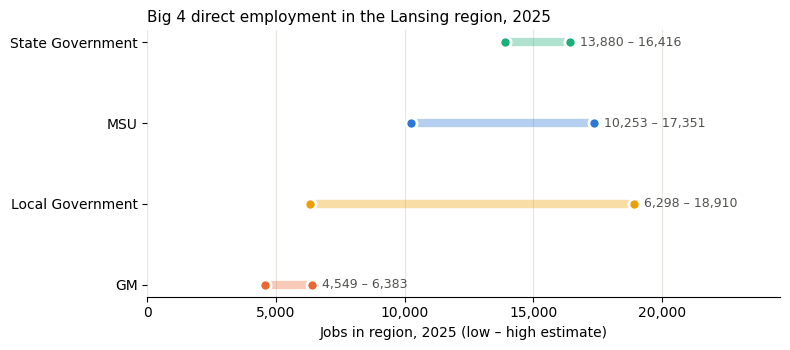

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = e1.sort_values("midpoint").index
for i, inst in enumerate(order):
    lo, hi = e1.loc[inst, ["low", "high"]]
    c = BIG4_COLORS[inst]
    ax.plot([lo, hi], [i, i], color=c, lw=6, solid_capstyle="round", alpha=0.35)
    ax.plot([lo, hi], [i, i], "o", color=c, ms=8, mec="white", mew=2)
    ax.text(hi + 400, i, f"{lo:,.0f} – {hi:,.0f}", va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Jobs in region, 2025 (low – high estimate)")
ax.set_xlim(0, e1["high"].max() * 1.3)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.set_title("Big 4 direct employment in the Lansing region, 2025", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 4. E4 — Employment trend, 2019 → 2025

Trend uses **one consistent QCEW series per institution** (the high-estimate definitions), so year-to-year changes are not mixed across sources. GM's best series (3361-based) starts in 2021, so the 2019 baseline uses the full auto cluster (336) as well.

In [8]:
trend = pd.DataFrame({
    "MSU (QCEW residual)": msu_high,
    "GM (QCEW est., 2021+)": gm_high,
    "GM auto cluster (336)": gm_cluster,
    "State Gov (own2 PA)": state_high,
    "Local Gov core (own3 PA)": local_core,
    "Local Gov broad (own3 all)": local_broad,
    "Region, all jobs": region_jobs,
})
e4 = pd.DataFrame({
    "2019": trend.loc[2019], "2025": trend.loc[2025],
    "change_2019_2025_pct": [pct_change(trend[c], 2019, 2025) for c in trend],
    "change_2021_2025_pct": [pct_change(trend[c], 2021, 2025) for c in trend],
})
e4

,2019,2025,change_2019_2025_pct,change_2021_2025_pct
MSU (QCEW residual),"17,053","17,351",1.75,11.88
"GM (QCEW est., 2021+)",NaN,"6,383",NaN,26.20
GM auto cluster (336),"7,233","9,298",28.55,21.89
State Gov (own2 PA),"13,962","16,416",17.58,23.78
Local Gov core (own3 PA),"5,902","6,298",6.71,10.72
Local Gov broad (own3 all),"17,787","18,910",6.31,10.99
"Region, all jobs","211,666","219,664",3.78,9.32


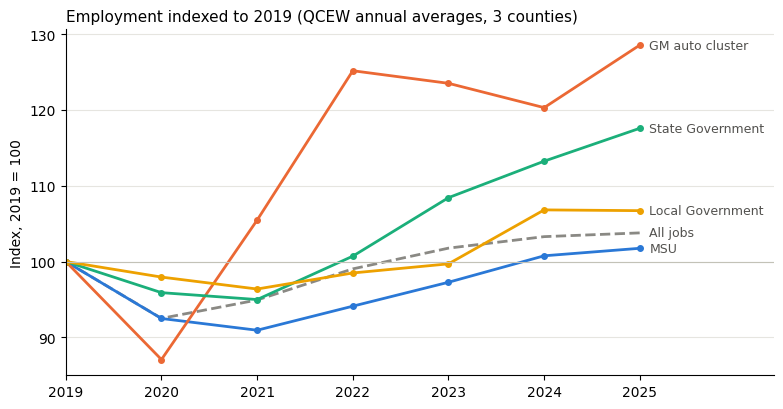

In [9]:
series = {
    "MSU": ("MSU (QCEW residual)", BIG4_COLORS["MSU"]),
    "GM auto cluster": ("GM auto cluster (336)", BIG4_COLORS["GM"]),
    "State Government": ("State Gov (own2 PA)", BIG4_COLORS["State Government"]),
    "Local Government": ("Local Gov core (own3 PA)", BIG4_COLORS["Local Government"]),
}
fig, ax = plt.subplots(figsize=(8, 4.2))
idx_region = index_to(trend["Region, all jobs"], 2019)
ax.plot(idx_region.index, idx_region, color=REGION_COLOR, lw=2, ls="--")
ax.text(2025.1, idx_region[2025], "All jobs", va="center", fontsize=9, color="#52514e")
for label, (col, color) in series.items():
    s = index_to(trend[col], 2019)
    ax.plot(s.index, s, color=color, lw=2, marker="o", ms=4)
    ax.text(2025.1, s[2025], label, va="center", fontsize=9, color="#52514e")
ax.axhline(100, color="#c3c2b7", lw=0.8)
ax.set_xlim(2019, 2026.4); ax.set_xticks(range(2019, 2026))
ax.set_ylabel("Index, 2019 = 100")
for s_ in ["top", "right"]:
    ax.spines[s_].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.set_title("Employment indexed to 2019 (QCEW annual averages, 3 counties)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 5. E5 — Concentration

In [10]:
big4_low, big4_high = e1["low"].sum(), e1["high"].sum()
print(f"Big 4 combined, {YEAR}: {big4_low:,.0f} – {big4_high:,.0f} jobs "
      f"= {big4_low/total_2025*100:.1f}% – {big4_high/total_2025*100:.1f}% of {total_2025:,.0f} regional jobs")

top10 = employers[employers.year == YEAR].copy()
top10["big4"] = top10["big4_flag"].isin(["MSU", "GM", "State Government"])
share_in_top10 = top10.loc[top10.big4, "employees"].sum() / top10["employees"].sum() * 100
print(f"Big 4 (excl. local gov) share of the LEAP top-10 employer headcount: {share_in_top10:.1f}%")
print(f"HHI of LEAP top-10 shares (pct of metro employment): {hhi(top10['pct_of_metro_employment']):.1f}")
top10[["rank_as_published", "employer", "employees", "pct_of_metro_employment", "big4_flag"]]

Big 4 combined, 2025: 34,980 – 59,060 jobs = 15.9% – 26.9% of 219,664 regional jobs
Big 4 (excl. local gov) share of the LEAP top-10 employer headcount: 54.8%
HHI of LEAP top-10 shares (pct of metro employment): 97.6


,rank_as_published,employer,employees,pct_of_metro_employment,big4_flag
0,1,STATE OF MICHIGAN,13880,6.57,State Government
2,2,MICHIGAN STATE UNIVERSITY,10253,4.85,MSU
4,3,UNIVERSITY OF MICHIGAN SPARROW HEALTH SYSTEM,9000,4.26,NaN
6,4,GENERAL MOTORS,4549,2.15,GM
8,5,MCLAREN HEALTH,3000,1.42,NaN
10,6,AUTO OWNERS,2720,1.29,NaN
12,7,PECKHAM,2510,1.19,NaN
13,8,JACKSON NATIONAL LIFE INS CO,2439,1.15,NaN
15,9,DART CONTAINER CORP,2000,0.95,NaN
16,10,LANSING COMMUNITY COLLEGE,1957,0.93,Local/Regional Gov (context)


## 6. Cross-check — how far apart are the sources?

LEAP (via ACFR Table 15) and QCEW measure different things: LEAP is a self-reported headcount for the Greater Lansing Region; QCEW counts covered jobs (positions) by establishment. The table below shows the gap for each institution and over time where both exist.

In [11]:
xcheck = pd.DataFrame({
    "LEAP 2016": [leap[("MICHIGAN STATE UNIVERSITY", 2016)], leap[("GENERAL MOTORS", 2016)], leap[("STATE OF MICHIGAN", 2016)]],
    "LEAP 2025": [leap_2025["MSU"], leap_2025["GM"], leap_2025["State Government"]],
    "QCEW 2025 (high est.)": [msu_high[2025], gm_high[2025], state_high[2025]],
}, index=["MSU", "GM", "State Government"])
xcheck["LEAP change 2016-25 %"] = (xcheck["LEAP 2025"] / xcheck["LEAP 2016"] - 1) * 100
xcheck["QCEW / LEAP"] = xcheck["QCEW 2025 (high est.)"] / xcheck["LEAP 2025"]
xcheck

,LEAP 2016,LEAP 2025,QCEW 2025 (high est.),LEAP change 2016-25 %,QCEW / LEAP
MSU,10725,10253,"17,351",-4.40,1.69
GM,5222,4549,"6,383",-12.89,1.40
State Government,13700,13880,"16,416",1.31,1.18


## 7. Save outputs

In [12]:
footprint = e1.join(e2).join(e3[["avg_annual_pay", "pay_ratio", "pay_basis"]])
footprint.insert(0, "year", YEAR)
footprint["region_total_jobs"] = total_2025
footprint.to_csv(OUT_DIR / "footprint_v0_2025.csv", index_label="institution")
trend.to_csv(OUT_DIR / "footprint_timeseries_2019_2025.csv", index_label="year")
print("Saved:", *(p.name for p in sorted(OUT_DIR.glob("footprint_*.csv"))), sep="\n  ")

Saved:
  footprint_robustness_2025.csv
  footprint_timeseries_2019_2025.csv
  footprint_v0_2025.csv


## 8. Findings (draft)

These are first-pass readings of the numbers above. They are descriptive, not causal.

1. **The Big 4 hold roughly one in six to one in four regional jobs.** Combined direct employment is about **35,000–59,000 jobs**, or **16%–27%** of the region's 219,664 covered jobs in 2025. The width of that range is itself a result: public sources do not agree on how big these institutions are.

2. **State Government is the best-measured institution** (13,900–16,400 jobs; the two sources are within 17%), and the largest *if* local government means general government only — the size ranking is not robust (see section 9). **MSU is second**, but its range is wide (10,300–17,400) because QCEW suppresses MSU directly and the high estimate is a residual. **Local Government** depends almost entirely on definition (6,300 general government vs 18,900 including schools and utilities) — a partner decision, not a data problem.

3. **Big 4 jobs pay well above the regional average** ($68,223): GM about **1.48×**, State Government **1.34×**, MSU **1.32×**; local general government is close to average (**0.95×**). High-wage jobs make the next question sharper: *where do these earners live and spend?* — that is notebook 02.

4. **Growth since 2019 is uneven (QCEW series only — LEAP disagrees for MSU and GM, see section 9).** All regional jobs grew **+3.8%**. State public administration grew **+17.6%** and the GM-anchored auto cluster **+28.5%** (volatile: −13% in 2020, then driven by Eaton County). MSU's QCEW series is nearly flat (**+1.7%**), lagging the region.

5. **The Big 4 framing leaves out a major anchor.** In LEAP's top-10 list, UM Health–Sparrow (9,000) is larger than GM (4,549). The three Big 4 institutions on that list account for **55%** of top-10 headcount; health care is the obvious missing anchor to raise with the partner.

6. **Sources point in different directions for GM.** LEAP shows GM down **13%** (2016→2025) while QCEW's auto cluster is up **28%** (2019→2025). Different periods and definitions explain part of it; the rest cannot be reconciled without GM's own plant headcounts. Flagged as a data gap.

_Note: 2025 State Government includes one imputed cell (Eaton, see section 2)._

## 9. Robustness — which conclusions hold across the range?

Every institution is a range, so each conclusion is tested the same way: **does it still hold at the low end and at the high end?** If yes, the public data are good enough for that conclusion and the exact number does not matter for the partner's decision. If not, the conclusion is flagged.

`test_A` / `test_B` = the low and high end of the range (E1, E2, E5), or two independent sources/definitions (E3, E4).

Verdicts: **Robust** = holds at both ends · **Directional** = same sign, very different size · **Not supported** = the ends disagree.

In [13]:
def verdict(lo_ok, hi_ok):
    return "Robust" if (lo_ok and hi_ok) else "Not supported"

rows = []

# E1 - size ranking at each end of the range
rank_lo = e1["low"].sort_values(ascending=False).index.tolist()
rank_hi = e1["high"].sort_values(ascending=False).index.tolist()
rows.append(dict(indicator="E1", claim="GM is the smallest of the Big 4",
                 at_low=" > ".join(rank_lo), at_high=" > ".join(rank_hi),
                 verdict=verdict(rank_lo[-1] == "GM", rank_hi[-1] == "GM")))
rows.append(dict(indicator="E1", claim="State Government is the largest of the Big 4",
                 at_low=rank_lo[0], at_high=rank_hi[0],
                 verdict=verdict(rank_lo[0] == "State Government", rank_hi[0] == "State Government")))

# E2 - GM share and Big 4 combined share
gm_lo, gm_hi = e2.loc["GM", "low_share_pct"], e2.loc["GM", "high_share_pct"]
rows.append(dict(indicator="E2", claim="GM is under 3% of regional jobs",
                 at_low=f"{gm_lo:.1f}%", at_high=f"{gm_hi:.1f}%", verdict=verdict(gm_lo < 3, gm_hi < 3)))
b_lo, b_hi = big4_low / total_2025 * 100, big4_high / total_2025 * 100
rows.append(dict(indicator="E5", claim="Big 4 hold at least 1 in 7 regional jobs (>14%)",
                 at_low=f"{b_lo:.1f}%", at_high=f"{b_hi:.1f}%", verdict=verdict(b_lo > 14, b_hi > 14)))

# E3 - pay above regional average; GM tested on two alternative QCEW definitions
cluster_pay = tri_county_sum(qcew_cell(qcew, OWN_PRIVATE, "336", "total_annual_wages"))[YEAR] / gm_cluster[YEAR]
gm_ratio_alt = cluster_pay / region_pay[YEAR]
rows.append(dict(indicator="E3", claim="GM jobs pay above the regional average",
                 at_low=f"{gm_ratio_alt:.2f}x (all of 336)", at_high=f"{e3.loc['GM','pay_ratio']:.2f}x (GM est.)",
                 verdict=verdict(gm_ratio_alt > 1, e3.loc["GM", "pay_ratio"] > 1)))
for inst in ["MSU", "State Government"]:
    r = e3.loc[inst, "pay_ratio"]
    rows.append(dict(indicator="E3", claim=f"{inst} jobs pay above the regional average",
                     at_low="no second source", at_high=f"{r:.2f}x",
                     verdict="Robust (one source)" if r > 1.1 else "Not supported"))

# E4 - direction of change: LEAP (2016->2025) vs QCEW (2019->2025)
qcew_change = {"MSU": e4.loc["MSU (QCEW residual)", "change_2019_2025_pct"],
               "GM": e4.loc["GM auto cluster (336)", "change_2019_2025_pct"],
               "State Government": e4.loc["State Gov (own2 PA)", "change_2019_2025_pct"]}
for inst, q in qcew_change.items():
    l = xcheck.loc[inst, "LEAP change 2016-25 %"]
    if np.sign(l) != np.sign(q):
        v = "Not supported"
    elif abs(q - l) > 10:
        v = "Directional"
    else:
        v = "Robust"
    rows.append(dict(indicator="E4", claim=f"{inst} employment grew",
                     at_low=f"LEAP 2016-25: {l:+.1f}%", at_high=f"QCEW 2019-25: {q:+.1f}%", verdict=v))

robust = pd.DataFrame(rows).rename(columns={"at_low": "test_A", "at_high": "test_B"})
robust.to_csv(OUT_DIR / "footprint_robustness_2025.csv", index=False)
robust

,indicator,claim,test_A,test_B,verdict
0,E1,GM is the smallest of the Big 4,State Government > MSU > Local Government > GM,Local Government > MSU > State Government > GM,Robust
1,E1,State Government is the largest of the Big 4,State Government,Local Government,Not supported
2,E2,GM is under 3% of regional jobs,2.1%,2.9%,Robust
3,E5,Big 4 hold at least 1 in 7 regional jobs (>14%),15.9%,26.9%,Robust
4,E3,GM jobs pay above the regional average,1.32x (all of 336),1.48x (GM est.),Robust
5,E3,MSU jobs pay above the regional average,no second source,1.32x,Robust (one source)
6,E3,State Government jobs pay above the regional a...,no second source,1.34x,Robust (one source)
7,E4,MSU employment grew,LEAP 2016-25: -4.4%,QCEW 2019-25: +1.7%,Not supported
8,E4,GM employment grew,LEAP 2016-25: -12.9%,QCEW 2019-25: +28.5%,Not supported
9,E4,State Government employment grew,LEAP 2016-25: +1.3%,QCEW 2019-25: +17.6%,Directional


### Reading the robustness table

**Trustworthy now (public data are enough):**
- **GM is the smallest Big 4 employer**, at roughly 2–3% of regional jobs. The exact GM headcount does not change this.
- **The Big 4 together hold at least one in seven regional jobs.**
- **Big 4 jobs pay above the regional average** — for GM under both QCEW definitions; for MSU and State Government on one source each, with a wide margin (≈1.3×).

**Questionable — needs further work before it goes in front of the partner:**
- **Which institution is largest.** State Government leads on LEAP numbers, but Local Government leads once schools and utilities are counted, and MSU's QCEW estimate is above State's. The ranking depends on definitions the partner has not yet confirmed (Partner question 2) and on MSU's residual estimate (closable with IPEDS HR).
- **Employment trends.** For **MSU and GM the two sources disagree on direction** (LEAP down, QCEW up). For State Government both say growth, but +1% vs +18%. Part of this is the different base years (2016 vs 2019); part is that the sources count different things. Report trends only as "QCEW series" and do not attribute them to the institution itself until a second source agrees.

**Implication for the scorecard:** use E1–E3 and E5 as levels with their ranges; treat E4 as *directional context*; do not publish a Big 4 size ranking until the local-government definition is settled.

## 10. Caveats and data gaps (feeds RQ4)

| # | Gap | Effect on this notebook | What would close it |
|---|---|---|---|
| 1 | QCEW suppresses state educational services (MSU) in Ingham | MSU high estimate is a residual, not a direct count | IPEDS HR total employees (fall staff survey); MSU HR headcount by work location |
| 2 | QCEW suppresses GM's Ingham plant (3361) | GM high estimate uses 336 − 3363 | GM plant headcounts from GM or UAW locals; partner request |
| 3 | LEAP top-employer list is self-reported, region-level, no method note | Low estimates may mix headcount and FTE | Ask LEAP how counts are collected |
| 4 | Local education (own 3, NAICS 611) suppressed in Ingham/Eaton | Cannot separate schools from other local units | Census ASPEP by government unit |
| 5 | Eaton state public administration suppressed for 2025 | One imputed cell (see note above) | Next QCEW release / Civil Service workforce report |
| 6 | Positions vs people | QCEW counts jobs; one person with two jobs counts twice | Not fixable with public data — state it |